# 02 - One instance from scratch

The complete analysis of the paper (Table 1) for one $N=16$ Bethe glass at $\beta_J=2.5$, computed from scratch in well under a minute:

1. the exact Gibbs measure (all $2^{16}$ configurations);
2. the classes (Sec. 4): sectors, glassy splits, their masses, overlaps and split variances $\Delta$;
3. the predicted decision times from the parents' leading eigenvalues $\lambda_P$ (binary-channel prediction);
4. trajectories generated endpoint first, $H_\gamma=\gamma Y+B_\gamma$ (Proposition 1);
5. partial commitments $p_\ell=p_{c_\ell(Y)}$ and $q_\ell=p_\ell/p_{\ell-1}$ along each trajectory, commitments and distinct events;
6. the information about each level, the measured decision times, and their comparison with the prediction.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path[:0] = [str(ROOT / 'code'), str(ROOT / 'experiments')]
np.set_printoptions(precision=4, suppress=True)
import exacttree as E

## 1. The target

In [2]:
N, beta_J, seed = 16, 2.5, 9
J = E.bethe_J(N, beta_J, seed)                      # random three-regular graph, Gaussian couplings, J = beta_J J0
M = E.ExactModel(J, 'bethe_N16')
print('number of edges:', int((np.abs(J) > 0).sum() // 2), '  leading eigenvalue of C0: lambda_1 = %.2f' % M.lam[0])

number of edges: 24   leading eigenvalue of C0: lambda_1 = 11.96


## 2. Classes (Sec. 4)

In [3]:
T = E.build_tree(M)
print('classes per level (both sectors):', T['n_classes'])
for l, splits in enumerate(T['level_info'], start=1):
    for s in splits:
        print(f'level {l}: parent mass {s["mass"]:.3f} -> children {s["masses"][0]/s["mass"]:.2f} / {s["masses"][1]/s["mass"]:.2f} of the parent;'
              f'  overlap within {s["qin"]:.2f}, between {s["qbt"]:.2f};  split variance Delta = {s["kappa"]:.2f}')

classes per level (both sectors): [2, 4, 6]
level 1: parent mass 1.000 -> children 0.74 / 0.26 of the parent;  overlap within 0.82, between 0.44;  split variance Delta = 2.02
level 2: parent mass 0.256 -> children 0.58 / 0.42 of the parent;  overlap within 0.92, between 0.42;  split variance Delta = 3.84


Each split is a cut by a hyperplane in the space of aligned configurations (Eq. `hyperplane`). The children of the first glassy split
differ mainly on a block of spins on which their magnetizations have opposite signs:

In [4]:
s = M.gauge(); lab1 = T['labels'][1]
W = M.p * (s > 0); W = W / W.sum()                                    # one sector, aligned configurations
kids = [c for c in np.unique(lab1) if (W * (lab1 == c)).sum() > 1e-12]
mus = [M.first_moment(W * (lab1 == c)) / (W * (lab1 == c)).sum() for c in kids]
print('magnetizations of the two glassy classes (one row each):'); print(np.round(np.array(mus), 2))
print('spins with opposite signs:', np.flatnonzero(np.sign(mus[0]) != np.sign(mus[1])))

magnetizations of the two glassy classes (one row each):
[[-0.99  0.97 -1.   -1.   -0.49 -0.99  0.99  0.94  1.   -0.99  0.94 -0.97
   0.49 -1.    1.    0.97]
 [ 0.95  1.   -0.8  -0.17 -0.85 -1.    1.    0.97  0.14 -1.    0.97 -0.99
   0.85  0.95  0.17  0.18]]
spins with opposite signs: [ 0 13]


## 3. Predicted decision times (binary-channel prediction)

In [5]:
xs, ws = np.polynomial.hermite_e.hermegauss(120); ws = ws / ws.sum()
def Ibin_frac(s):
    s = np.atleast_1d(s)[:, None]
    return (np.log(2) - (np.logaddexp(0, -2 * (s + np.sqrt(s) * xs[None, :])) * ws).sum(1)) / np.log(2)
chans = E.parent_channels(M, T)             # per level: masses, entropies and leading eigenvalues lambda_P of the parents that split
gg = np.geomspace(1e-3, 20, 2000)
def predicted_curve(ch):
    w = np.array([c['pi'] * c['H'] for c in ch]); w = w / w.sum()
    return sum(wi * Ibin_frac(gg * c['kappa']) for wi, c in zip(w, ch))
pred = [float(gg[np.argmax(predicted_curve(ch) >= 0.5)]) for ch in chans]
for l, ch in enumerate(chans):
    print(f'level {l}: parents lambda_P = {[round(c["kappa"], 2) for c in ch]}  ->  predicted gamma_1/2 = {pred[l]:.3f}')

level 0: parents lambda_P = [11.96]  ->  predicted gamma_1/2 = 0.088
level 1: parents lambda_P = [2.41, 2.41]  ->  predicted gamma_1/2 = 0.434
level 2: parents lambda_P = [3.88, 3.88]  ->  predicted gamma_1/2 = 0.270


## 4. Trajectories, generated endpoint first

In [6]:
rng = np.random.default_rng(1)
g = np.concatenate([[0.0], np.geomspace(0.02 / N, 5.0, 30)])
R = E.run_paths(M, T, g, 256, rng)          # endpoints stratified over the finest classes, H = gamma Y + B, exact class posteriors
print('trajectories:', len(R['Y']), '  grid points:', len(g))

trajectories: 256   grid points: 31


## 5. Partial commitments along the endpoint's branch

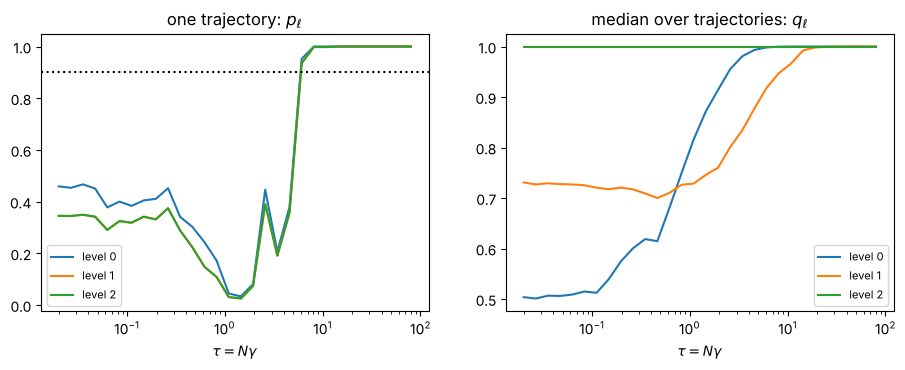

mean commitments per trajectory 2.25, mean distinct events 1.64


In [7]:
L = len(T['labels']); n = len(R['Y']); tau = N * g
p = np.stack([R['post'][l][np.arange(n), :, R['plant'][l]] for l in range(L)], -1)      # p_l = p_{c_l(Y)}
q = p.copy(); q[:, :, 1:] = p[:, :, 1:] / np.maximum(p[:, :, :-1], 1e-12)                 # q_l = p_l / p_{l-1}
i0 = 0
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for l in range(L):
    ax[0].semilogx(tau[1:], p[i0, 1:, l], label=f'level {l}'); ax[1].semilogx(tau[1:], np.median(q[:, 1:, l], 0), label=f'level {l}')
ax[0].axhline(.9, ls=':', c='k'); ax[0].set_title('one trajectory: $p_\\ell$'); ax[1].set_title('median over trajectories: $q_\\ell$')
for a in ax: a.set_xlabel('$\\tau=N\\gamma$'); a.legend(fontsize=8)
plt.show()
# commitments (first time p_l >= 0.9) at levels where the branch splits, merged into distinct events within a factor 2
split = np.ones((n, L), bool)
for l in range(1, L): split[:, l] = np.abs(p[:, 0, l] - p[:, 0, l - 1]) > 1e-12
ncom, nev = [], []
for i in range(n):
    tc = sorted(g[np.argmax(p[i, :, l] >= .9)] for l in range(L) if split[i, l] and (p[i, :, l] >= .9).any())
    ncom.append(len(tc)); nev.append(1 + sum(b / a >= 2 for a, b in zip(tc[:-1], tc[1:])) if tc else 0)
print('mean commitments per trajectory %.2f, mean distinct events %.2f' % (np.average(ncom, weights=R['w']), np.average(nev, weights=R['w'])))

## 6. Information per level and the prediction

level 0: measured gamma_1/2 = 0.102   predicted = 0.088   ratio = 1.16
level 1: measured gamma_1/2 = 0.463   predicted = 0.434   ratio = 1.07
level 2: measured gamma_1/2 = 0.312   predicted = 0.270   ratio = 1.16


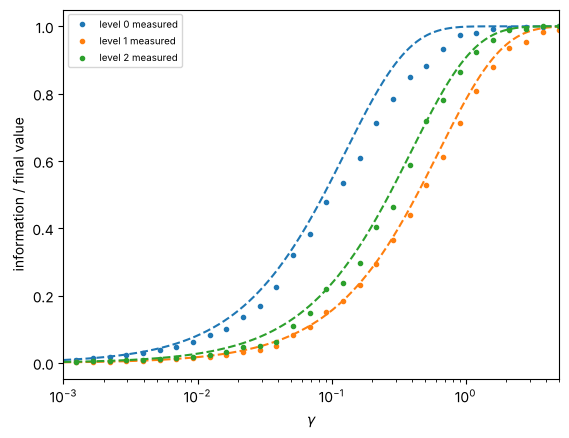

In [8]:
I, dI, Hl, dH = E.level_information(M, T, R)
frac = np.array([dI[l] / dH[l] for l in range(L)])
meas = [E.half_time(g, frac[l]) for l in range(L)]
for l in range(L):
    print(f'level {l}: measured gamma_1/2 = {meas[l]:.3f}   predicted = {pred[l]:.3f}   ratio = {meas[l] / pred[l]:.2f}')
for l in range(L):
    plt.semilogx(g[1:], frac[l, 1:], 'o', ms=3, label=f'level {l} measured'); plt.semilogx(gg, predicted_curve(chans[l]), '--', color=plt.gca().lines[-1].get_color())
plt.xlabel('$\\gamma$'); plt.ylabel('information / final value'); plt.legend(fontsize=7); plt.xlim(1e-3, 5); plt.show()